In [7]:
# pip install pyuvdata
# pip install pooch
# pip install hera_pspec

In [3]:
%matplotlib inline
# standard imports
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from scipy import interpolate
import warnings
from astropy.time import Time
warnings.filterwarnings('ignore', module='hera_sim')
warnings.filterwarnings('ignore', category=RuntimeWarning)

# HERA-Stack
# import hera_pspec as hp

# PyUVData
from pyuvdata import UVData
from pyuvdata.datasets import fetch_data

In [4]:
uvd = UVData()
uvd.read_uvh5(filename = 'zen.2459122.34011.mini.sum.uvh5')
data = uvd.data_array

In [5]:
waterfall_data = uvd.get_data((1, 2, uvd.polarization_array[0]))

waterfall_times = Time(uvd.get_times((1, 2, uvd.polarization_array[0])), format="jd").iso

In [26]:
np.abs(waterfall_data)

array([[346209.27022828, 347659.17593528, 355019.06888645, ...,
         22943.60052389,  17454.49237303,  34646.89746572],
       [343930.60750244, 347960.86454226, 352969.24724542, ...,
         25398.81156669,  19291.12396933,  32631.49083324],
       [345382.95922063, 349423.08120815, 357510.24507278, ...,
         21470.74754171,  22712.60920722,  37138.32016933],
       ...,
       [355442.19049094, 357889.25407869, 360253.07047685, ...,
         16898.66574615,  14886.81379611,  26585.45040055],
       [353146.77651368, 357441.81815367, 362213.50315249, ...,
         18620.02303973,  11460.01788829,  27335.81001178],
       [354979.55404924, 358477.80544965, 362418.99783124, ...,
         19154.03103788,   7428.42358781,  22562.17447411]],
      shape=(20, 1536))

In [20]:
waterfall_times

array(['2020-09-29 20:09:41.092', '2020-09-29 20:09:50.755',
       '2020-09-29 20:10:00.419', '2020-09-29 20:10:10.083',
       '2020-09-29 20:10:19.747', '2020-09-29 20:10:29.410',
       '2020-09-29 20:10:39.074', '2020-09-29 20:10:48.738',
       '2020-09-29 20:10:58.401', '2020-09-29 20:11:08.065',
       '2020-09-29 20:11:17.729', '2020-09-29 20:11:27.392',
       '2020-09-29 20:11:37.056', '2020-09-29 20:11:46.720',
       '2020-09-29 20:11:56.383', '2020-09-29 20:12:06.047',
       '2020-09-29 20:12:15.711', '2020-09-29 20:12:25.374',
       '2020-09-29 20:12:35.038', '2020-09-29 20:12:44.702'], dtype='<U23')

(300.0, 500.0)

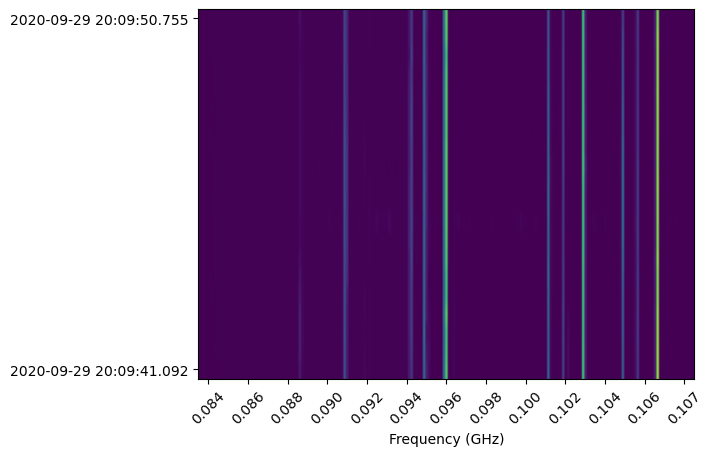

In [30]:
fig, ax = plt.subplots()
ax.imshow(np.abs(waterfall_data), origin = 'lower', interpolation = None)
ax.set_aspect('auto')
ax.set_yticks([0, waterfall_times.size - 1])
ax.set_yticklabels([waterfall_times[0], waterfall_times[1]])

freq_tick_inds = np.concatenate((np.arange(0, uvd.Nfreqs, 16), [uvd.Nfreqs-1]))
ax.set_xticks(freq_tick_inds)
ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds]*1e-9])
ax.tick_params(axis='x', labelrotation=45)
ax.set_xlabel("Frequency (GHz)")

ax.set_xlim(300,500)

In [ ]:
plt.plot(